<a href="https://colab.research.google.com/github/Abeer-24/NLP/blob/main/GloVe_Embeddings_loading_and_vector_representation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
import urllib.request
import zipfile
import os

In [8]:
!pip install -q gensim

import gensim.downloader as api

print("Downloading GloVe embeddings...")

glove_model = api.load("glove-wiki-gigaword-100")

print("GloVe embeddings loaded successfully!")
print("Total words:", len(glove_model))
print("Vector dimensions:", glove_model.vector_size)

[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe embeddings loaded successfully!
Total words: 400000
Vector dimensions: 100


In [9]:
glove_vectors = glove_model

print("Total words loaded:", len(glove_vectors))
print("Vector dimensions:", glove_vectors.vector_size)

Total words loaded: 400000
Vector dimensions: 100


In [10]:
word = "computer"

if word in glove_vectors:
    print("Word:", word)
    print("GloVe Vector:")
    print(glove_vectors[word])
else:
    print("Word not found!")

Word: computer
GloVe Vector:
[-1.6298e-01  3.0141e-01  5.7978e-01  6.6548e-02  4.5835e-01 -1.5329e-01
  4.3258e-01 -8.9215e-01  5.7747e-01  3.6375e-01  5.6524e-01 -5.6281e-01
  3.5659e-01 -3.6096e-01 -9.9662e-02  5.2753e-01  3.8839e-01  9.6185e-01
  1.8841e-01  3.0741e-01 -8.7842e-01 -3.2442e-01  1.1202e+00  7.5126e-02
  4.2661e-01 -6.0651e-01 -1.3893e-01  4.7862e-02 -4.5158e-01  9.3723e-02
  1.7463e-01  1.0962e+00 -1.0044e+00  6.3889e-02  3.8002e-01  2.1109e-01
 -6.6247e-01 -4.0736e-01  8.9442e-01 -6.0974e-01 -1.8577e-01 -1.9913e-01
 -6.9226e-01 -3.1806e-01 -7.8565e-01  2.3831e-01  1.2992e-01  8.7721e-02
  4.3205e-01 -2.2662e-01  3.1549e-01 -3.1748e-01 -2.4632e-03  1.6615e-01
  4.2358e-01 -1.8087e+00 -3.6699e-01  2.3949e-01  2.5458e+00  3.6111e-01
  3.9486e-02  4.8607e-01 -3.6974e-01  5.7282e-02 -4.9317e-01  2.2765e-01
  7.9966e-01  2.1428e-01  6.9811e-01  1.1262e+00 -1.3526e-01  7.1972e-01
 -9.9605e-04 -2.6842e-01 -8.3038e-01  2.1780e-01  3.4355e-01  3.7731e-01
 -4.0251e-01  3.3124e-

In [11]:
words = ["king", "queen", "man", "woman"]

for word in words:
    if word not in glove_vectors:
        raise ValueError(f"{word} not found in GloVe vocabulary")

vectors = np.array([glove_vectors[word] for word in words])

similarity_matrix = cosine_similarity(vectors)

print("Cosine Similarity Matrix:")
print(np.round(similarity_matrix, 3))

Cosine Similarity Matrix:
[[1.    0.751 0.512 0.366]
 [0.751 1.    0.474 0.51 ]
 [0.512 0.474 1.    0.832]
 [0.366 0.51  0.832 1.   ]]


In [13]:
def find_similar_words(word, top_n=5):

    if word not in glove_vectors:
        print("Word not found!")
        return

    similar_words = glove_vectors.most_similar(
        word,
        topn=top_n
    )

    print("Words similar to:", word)

    for similar_word, score in similar_words:
        print(similar_word, ":", round(float(score), 3))


find_similar_words("computer")

Words similar to: computer
computers : 0.875
software : 0.837
technology : 0.764
pc : 0.737
hardware : 0.729


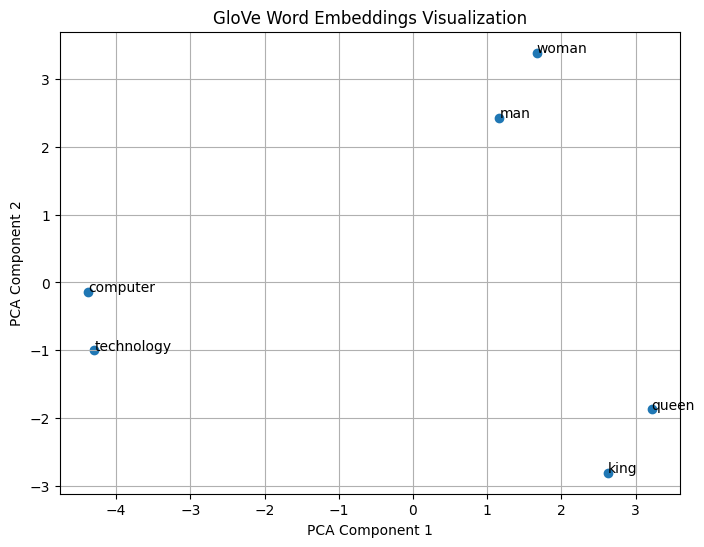

In [14]:
words = ["king", "queen", "man", "woman", "computer", "technology"]

vectors = np.array([glove_vectors[word] for word in words])

# Reduce 100 dimensions to 2 using PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(vectors)

plt.figure(figsize=(8, 6))

plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1])

for i, word in enumerate(words):
    plt.annotate(
        word,
        (reduced_vectors[i, 0], reduced_vectors[i, 1])
    )

plt.title("GloVe Word Embeddings Visualization")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.grid()
plt.show()